# Uneven Ground

The source is the Trans Rights Indicator Project (TRIP), built by political scientist Myles Williamson, a dataset that presents the law of 173 countries, for every year from 2000 to 2021, answering thirteen yes/no.

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../src/data/raw/trans_rights_worldwide.csv")
df = df[df["year"].between(2000, 2021)]
df.head()


,country_name,country_text_id,country_id,year,v2x_polyarchy,v2x_regime,e_boix_regime,e_polity2,e_regionpol,e_regionpol_6C,...,lgb_unions,lgb_jointadoption,lgb_secondparentadoption,lgb_score,lgb_percent,no_dircrim,no_indcrim,nophys,nopsych,nodiv
1,Mexico,MEX,3.0,2000.0,0.667,Electoral Democracy,1.0,8.0,Latin America,L. American and the Caribbean,...,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0
2,Mexico,MEX,3.0,2001.0,0.684,Electoral Democracy,1.0,8.0,Latin America,L. American and the Caribbean,...,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0
3,Mexico,MEX,3.0,2002.0,0.694,Electoral Democracy,1.0,8.0,Latin America,L. American and the Caribbean,...,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0
4,Mexico,MEX,3.0,2003.0,0.702,Electoral Democracy,1.0,8.0,Latin America,L. American and the Caribbean,...,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0
5,Mexico,MEX,3.0,2004.0,0.710,Electoral Democracy,1.0,8.0,Latin America,L. American and the Caribbean,...,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0


### The 13 indicators

Each indicator adds 1 point to `trip_score` when the country's law has the protective value.

| Column | What it means | Scores a point when |
|---|---|---|
| **Criminalization** | | |
| `dir_crim` | Law directly criminalizes trans people (e.g. bans on "cross-dressing" or "imitating the opposite sex") | 0 (no) |
| `ind_crim` | Law indirectly criminalizes trans people (e.g. sodomy or public-morality laws used against them) | 0 (no) |
| **Recognition** | | |
| `gmc` | Legal gender marker change is possible | 1 (yes) |
| `gmcphys` | Gender change requires surgery or another physical requirement | 0 (no) |
| `gmcpsych` | Gender change requires a psychiatric diagnosis | 0 (no) |
| `gmcdiv` | Gender change requires being unmarried / divorcing | 0 (no) |
| `nb3g` | A nonbinary or third-gender marker is available | 1 (yes) |
| **Protection** | | |
| `adp_general` | General anti-discrimination law covering gender identity | 1 (yes) |
| `adp_employment` | Anti-discrimination protection in employment | 1 (yes) |
| `adp_education` | Anti-discrimination protection in education | 1 (yes) |
| `adp_healthcare` | Anti-discrimination protection in healthcare | 1 (yes) |
| `adp_housing` | Anti-discrimination protection in housing | 1 (yes) |
| `adp_constitution` | Constitutional protection for gender identity | 1 (yes) |

For `gmcphys`, `gmcpsych` and `gmcdiv`, a value of 2 means "not applicable": the country has no legal gender change at all.

In [135]:
# the value that earns the point, for each indicator
held_value = {
    "dir_crim": 0, "ind_crim": 0, "gmc": 1, "gmcphys": 0, "gmcpsych": 0, "gmcdiv": 0,
    "nb3g": 1, "adp_general": 1, "adp_employment": 1, "adp_education": 1,
    "adp_healthcare": 1, "adp_housing": 1, "adp_constitution": 1,
}
indicator_labels = {
    "dir_crim": "No direct criminalization", "ind_crim": "No indirect criminalization",
    "gmc": "Legal gender marker change", "gmcphys": "No surgery requirement",
    "gmcpsych": "No diagnosis requirement", "gmcdiv": "No divorce requirement",
    "nb3g": "Nonbinary / third gender marker", "adp_general": "General anti-discrimination law",
    "adp_employment": "Protection in employment", "adp_education": "Protection in education",
    "adp_healthcare": "Protection in healthcare", "adp_housing": "Protection in housing",
    "adp_constitution": "Constitutional protection",
}

## Exploring the data


### Shape and columns


In [136]:
print(df.shape)
print(df.columns.tolist())


(3795, 51)
['country_name', 'country_text_id', 'country_id', 'year', 'v2x_polyarchy', 'v2x_regime', 'e_boix_regime', 'e_polity2', 'e_regionpol', 'e_regionpol_6C', 'dir_crim', 'ind_crim', 'gmc', 'gmcpr', 'gmcphys', 'gmcpsych', 'gmcdiv', 'nb3g', 'adp_general', 'adp_constitution', 'adp_employment', 'adp_education', 'adp_healthcare', 'adp_housing', 'trip_score', 'trip_percent', 'wb_gdppc', 'lgdppc_wb', 'religiosity_percent', 'relpc_rcs', 'chrpc_rcs', 'muspc_rcs', 'nrepc_rcs', 'lgb_legal', 'lgb_const', 'lgb_broad', 'lgb_employ', 'lgb_hatecrime', 'lgb_incitement', 'lgb_banconv', 'lgb_marriage', 'lgb_unions', 'lgb_jointadoption', 'lgb_secondparentadoption', 'lgb_score', 'lgb_percent', 'no_dircrim', 'no_indcrim', 'nophys', 'nopsych', 'nodiv']


### Countries and years covered


In [137]:
print("countries:", df["country_text_id"].nunique())
print("years:", df["year"].min(), "to", df["year"].max())


countries: 173
years: 2000.0 to 2021.0


### Correlation between all the numeric columns


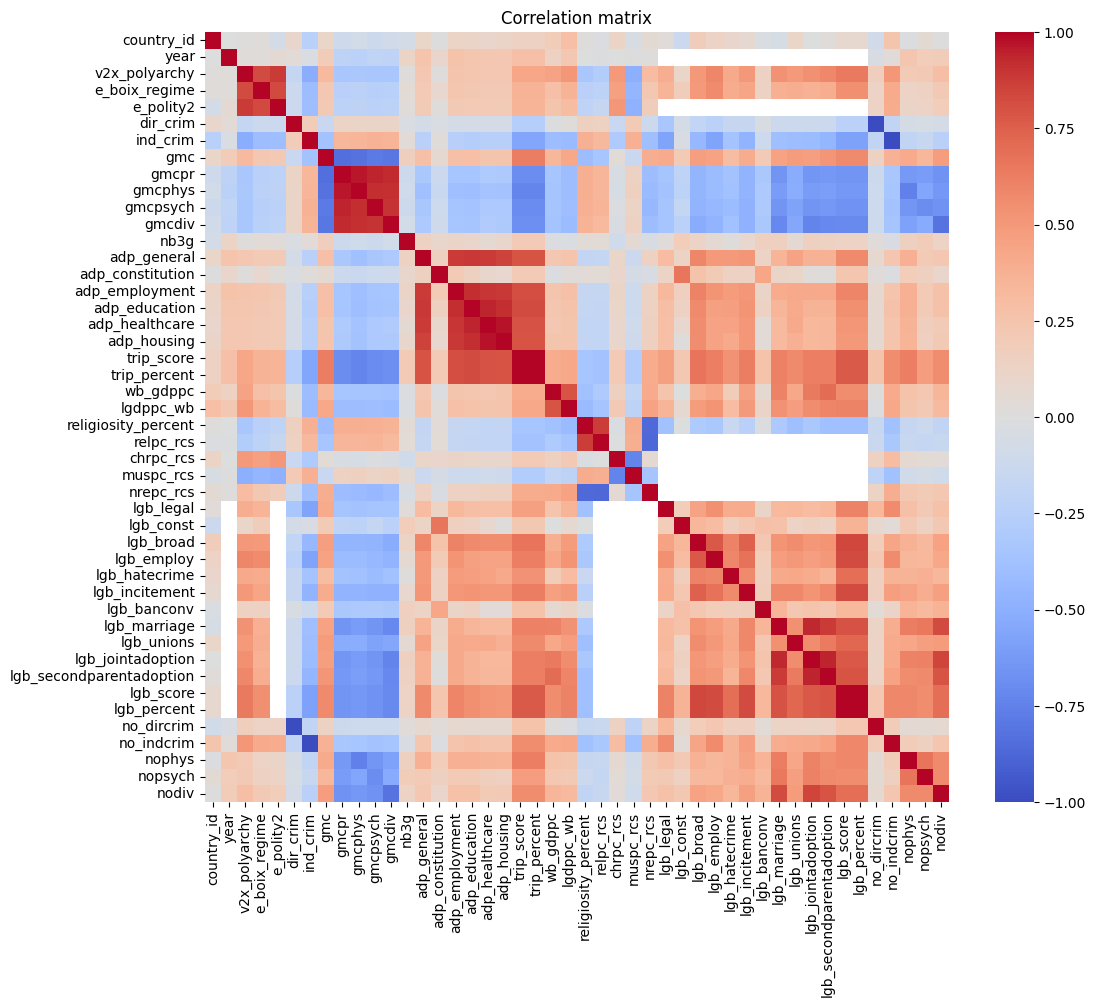

In [138]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()


### What correlates most with trip_score?


trip_percent      1.000000
adp_education     0.824965
adp_employment    0.816334
adp_healthcare    0.797145
adp_general       0.795133
adp_housing       0.793716
lgb_score         0.771464
lgb_percent       0.771464
lgb_broad         0.669453
lgb_incitement    0.632439
Name: trip_score, dtype: float64


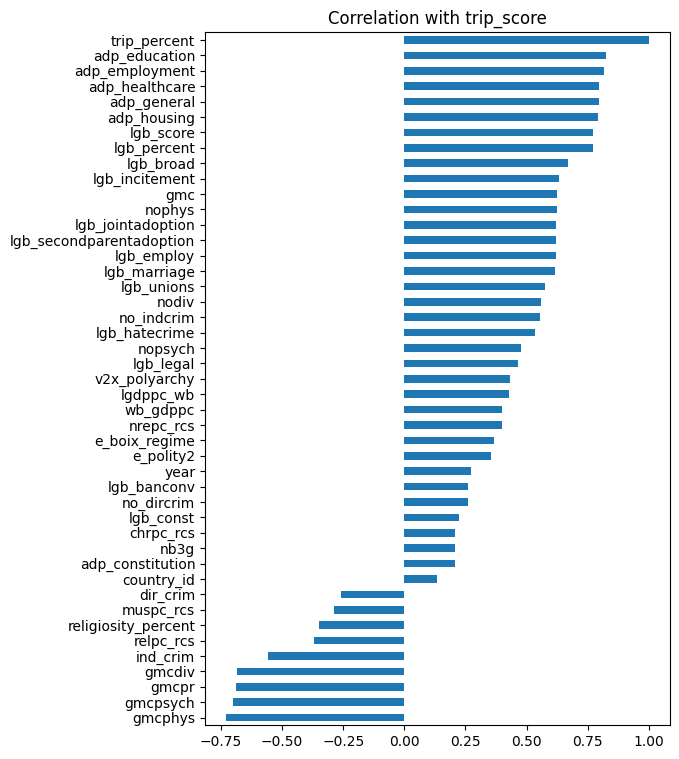

In [139]:
trip_corr = corr["trip_score"].drop("trip_score").sort_values(ascending=False)
print(trip_corr.head(10))

trip_corr.sort_values().plot.barh(figsize=(6, 9))
plt.title("Correlation with trip_score")
plt.show()


### Which countries changed the most, 2000 to 2021?


In [140]:
scores_2000 = df[df["year"] == 2000][["country_text_id", "country_name", "trip_score"]]
scores_2021 = df[df["year"] == 2021][["country_text_id", "trip_score"]]

change = scores_2000.merge(scores_2021, on="country_text_id", suffixes=("_2000", "_2021"))
change["change"] = change["trip_score_2021"] - change["trip_score_2000"]
change = change.sort_values("change")

print("Biggest drops:")
print(change.head(5)[["country_name", "trip_score_2000", "trip_score_2021"]])
print("\nBiggest gains:")
print(change.tail(5)[["country_name", "trip_score_2000", "trip_score_2021"]])


Biggest drops:
          country_name  trip_score_2000  trip_score_2021
47           Indonesia              1.0              0.0
46            Cambodia              2.0              1.0
108         The Gambia              1.0              0.0
140  Equatorial Guinea              2.0              1.0
148             Kuwait              1.0              0.0

Biggest gains:
    country_name  trip_score_2000  trip_score_2021
131      Belgium              2.0             11.0
93       Uruguay              2.0             12.0
23      Pakistan              1.0             11.0
35        Kosovo              NaN              7.0
155   Montenegro              NaN              8.0


### Average score by region, 2000 vs 2021


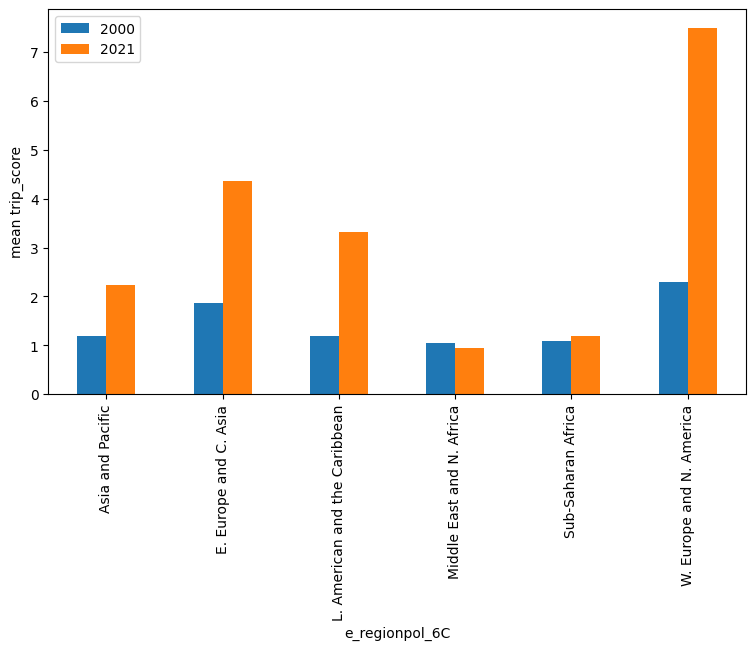

In [141]:
region_2000 = df[df["year"] == 2000].groupby("e_regionpol_6C")["trip_score"].mean()
region_2021 = df[df["year"] == 2021].groupby("e_regionpol_6C")["trip_score"].mean()

region_compare = pd.DataFrame({"2000": region_2000, "2021": region_2021})
region_compare.plot.bar(figsize=(9, 5))
plt.ylabel("mean trip_score")
plt.show()


### When did countries add a nonbinary / third-gender option?


In [142]:
nb_rows = df[df["nb3g"] == 1]
first_year = nb_rows.groupby("country_name")["year"].min().sort_values()
print(first_year)


country_name
Pakistan      2009.0
Nepal         2012.0
Bangladesh    2014.0
India         2014.0
Malta         2017.0
Uruguay       2018.0
Iceland       2019.0
Argentina     2021.0
Name: year, dtype: float64


---
## Section 1: "What the world's laws say about trans people"


### How many countries have a score in 2000 and in 2021?

In [143]:
d2000 = df[(df["year"] == 2000) & df["trip_score"].notna()]
d2021 = df[(df["year"] == 2021) & df["trip_score"].notna()]
print(len(d2000), "countries in 2000 |", len(d2021), "countries in 2021")

170 countries in 2000 | 173 countries in 2021


### The average vs. the rest of the distribution

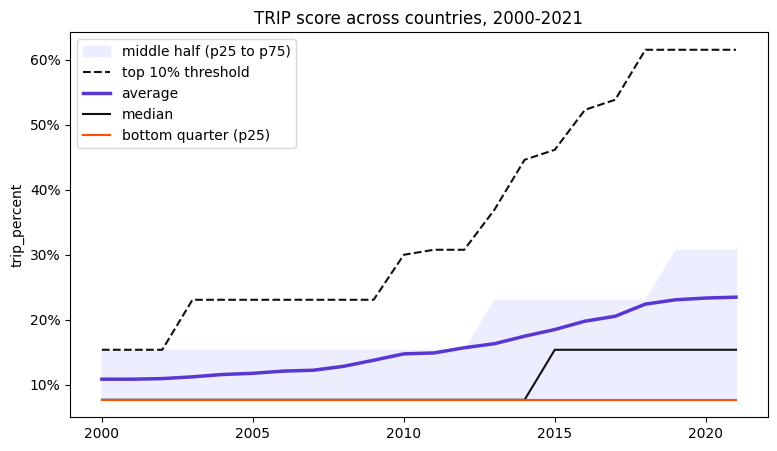

In [144]:
from matplotlib.ticker import PercentFormatter

stats = df.dropna(subset=["trip_percent"]).groupby("year")["trip_percent"].describe(percentiles=[0.25, 0.5, 0.75, 0.9])

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(stats.index, stats["25%"], stats["75%"], color="#ECEDFF", label="middle half (p25 to p75)")
ax.plot(stats.index, stats["90%"], color="#111111", ls="--", label="top 10% threshold")
ax.plot(stats.index, stats["mean"], color="#5A37D1", lw=2.5, label="average")
ax.plot(stats.index, stats["50%"], color="#111111", label="median")
ax.plot(stats.index, stats["25%"], color="#FF4E00", label="bottom quarter (p25)")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("trip_percent")
ax.set_title("TRIP score across countries, 2000-2021")
ax.legend(loc="upper left")
plt.show()

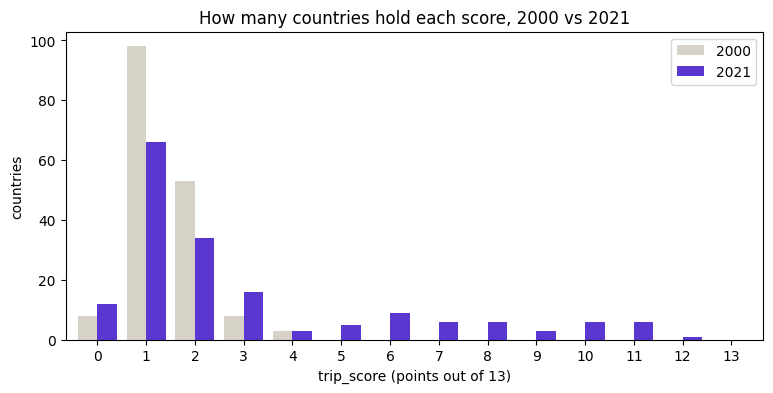

In [145]:
counts = pd.DataFrame({
    "2000": d2000["trip_score"].value_counts(),
    "2021": d2021["trip_score"].value_counts(),
}).reindex(range(14), fill_value=0)

counts.plot.bar(figsize=(9, 4), color=["#D6D2C8", "#5A37D1"], rot=0, width=0.8)
plt.xlabel("trip_score (points out of 13)")
plt.ylabel("countries")
plt.title("How many countries hold each score, 2000 vs 2021")
plt.show()

### How many of them scored only 1 point (just the no-criminalization indicator)?


In [146]:
only_one_point = d2000[d2000["trip_score"] == 1]
print(len(only_one_point))


98


### How many countries directly criminalized trans people in 2000?


In [147]:
print(int(d2000["dir_crim"].sum()))


8


### Average score, 2000 vs 2021


In [148]:
mean_2000 = d2000["trip_percent"].mean()
mean_2021 = d2021["trip_percent"].mean()
print(f"{mean_2000:.1%} -> {mean_2021:.1%}")
print(f"{mean_2021 / mean_2000:.1f} times higher")


10.9% -> 23.5%
2.2 times higher


### Median country, 2000 / 2015 / 2021


In [149]:
for year in [2000, 2015, 2021]:
    med = df[df["year"] == year]["trip_percent"].median()
    print(year, f"{med:.1%}", "=", round(med * 13), "of 13 points")


2000 7.7% = 1 of 13 points
2015 15.4% = 2 of 13 points
2021 15.4% = 2 of 13 points


### Middle half of countries (25th to 75th percentile)


In [150]:
p25_2000 = np.percentile(d2000["trip_percent"].dropna(), 25)
p75_2000 = np.percentile(d2000["trip_percent"].dropna(), 75)
p25_2021 = np.percentile(d2021["trip_percent"].dropna(), 25)
p75_2021 = np.percentile(d2021["trip_percent"].dropna(), 75)

print(f"2000: p25 = {p25_2000:.1%}, p75 = {p75_2000:.1%}")
print(f"2021: p25 = {p25_2021:.1%}, p75 = {p75_2021:.1%}")


2000: p25 = 7.7%, p75 = 15.4%
2021: p25 = 7.7%, p75 = 30.8%


### Top 10% threshold, 2000 vs 2021


In [151]:
p90_2000 = np.percentile(d2000["trip_percent"].dropna(), 90)
p90_2021 = np.percentile(d2021["trip_percent"].dropna(), 90)
print(f"{p90_2000:.1%} -> {p90_2021:.1%}")


15.4% -> 61.5%


### How many countries ended 2021 with the exact score they started with in 2000?


In [152]:
both_years = scores_2000.merge(scores_2021, on="country_text_id", suffixes=("_2000", "_2021"))
unchanged = both_years[both_years["trip_score_2000"] == both_years["trip_score_2021"]]
print(len(unchanged))


93


### And how many rewrote their laws, and how often?

In [153]:
yearly = df.sort_values(["country_text_id", "year"]).copy()
yearly["change"] = yearly.groupby("country_text_id")["trip_score"].diff()

gain_years = yearly[yearly["change"] > 0].groupby("country_name").size()
print(len(gain_years), "countries gained points at some point")
print((gain_years >= 2).sum(), "of them gained in more than one year")

80 countries gained points at some point
36 of them gained in more than one year


### How much did the middle 50% spread out (IQR)?


In [154]:
iqr_2000 = p75_2000 - p25_2000
iqr_2021 = p75_2021 - p25_2021
print(f"{iqr_2000:.1%} -> {iqr_2021:.1%}")
print(f"{iqr_2021 / iqr_2000:.0f} times wider")


7.7% -> 23.1%
3 times wider


---
## Section 2: "A map of exceptions"


### Every 2021 score, by region

Each dot is a country. The purple tick is the region's average. Countries 4.5 points or more away from their region's average are labelled.

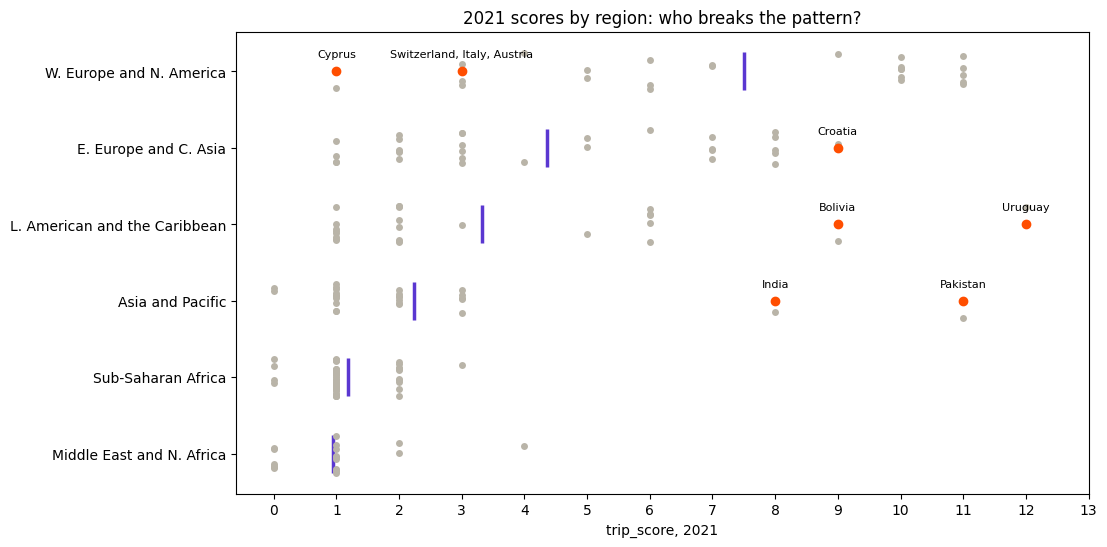

In [155]:
regional = d2021.copy()
regional["region_mean"] = regional.groupby("e_regionpol_6C")["trip_score"].transform("mean")
regional["distance"] = regional["trip_score"] - regional["region_mean"]
order = regional.groupby("e_regionpol_6C")["region_mean"].first().sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(11, 6))
sns.stripplot(data=regional, x="trip_score", y="e_regionpol_6C", order=order,
              color="#B9B4A8", jitter=0.25, size=5, ax=ax)
for i, region in enumerate(order):
    ax.plot(regional[regional["e_regionpol_6C"] == region]["region_mean"].iloc[0], i,
            marker="|", ms=28, mew=2.5, color="#5A37D1")

exceptions = regional[regional["distance"].abs() >= 4.5]
for (region, score), group in exceptions.groupby(["e_regionpol_6C", "trip_score"]):
    y = order.index(region)
    ax.scatter(score, y, color="#FF4E00", zorder=3)
    ax.annotate(", ".join(group["country_name"]), (score, y), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=8)

ax.set_xticks(range(14))
ax.set_xlabel("trip_score, 2021")
ax.set_ylabel("")
ax.set_title("2021 scores by region: who breaks the pattern?")
plt.show()

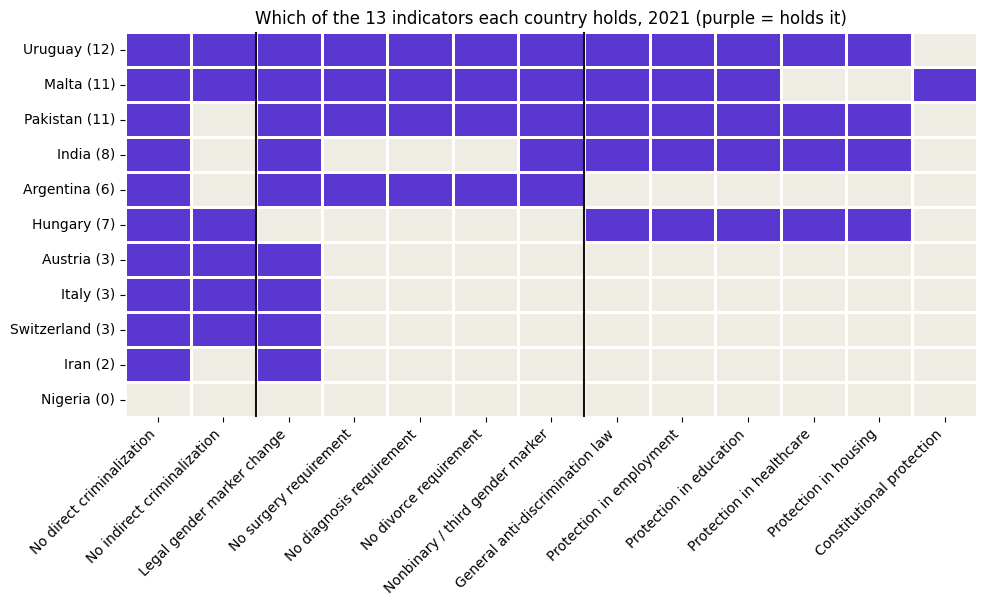

In [156]:
named = ["Uruguay", "Malta", "Pakistan", "India", "Argentina", "Hungary",
         "Austria", "Italy", "Switzerland", "Iran", "Nigeria"]

named_rows = d2021.set_index("country_name").loc[named]
held_grid = named_rows[list(held_value)].eq(pd.Series(held_value)).astype(int)
held_grid.index = [f"{name} ({score:.0f})" for name, score in named_rows["trip_score"].items()]
held_grid.columns = [indicator_labels[c] for c in held_grid.columns]

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(held_grid, cmap=ListedColormap(["#EFECE4", "#5A37D1"]), cbar=False,
            linewidths=1, linecolor="white", ax=ax)
ax.axvline(2, color="#111111", lw=1.5)
ax.axvline(7, color="#111111", lw=1.5)
ax.set_title("Which of the 13 indicators each country holds, 2021 (purple = holds it)")
plt.xticks(rotation=45, ha="right")
plt.show()

Read across a row and the same score turns out to mean very different things:

- **Argentina** has every recognition indicator and none of the six protections: recognition without protection.
- **Iran** holds two indicators: no direct criminalization, and a legal gender change that comes with all three conditions attached.
- **Austria, Italy and Switzerland** have no protection at all, despite being in the top region.
- **Hungary** has lost legal gender change, which raises the question of *when*.
- **Malta** is the only one here with a constitutional protection.
- **Nigeria** is the only one of these with direct criminalization.

### Where are the 13 highest scorers in 2021?


In [157]:
top13 = d2021.nlargest(13, "trip_score")
print(top13[["country_name", "e_regionpol_6C", "trip_score"]])
print("\nWestern Europe/N. America count:", (top13["e_regionpol_6C"] == "W. Europe and N. America").sum())


        country_name                 e_regionpol_6C  trip_score
2172         Uruguay  L. American and the Caribbean        12.0
551         Pakistan               Asia and Pacific        11.0
1574          France       W. Europe and N. America        11.0
3046         Belgium       W. Europe and N. America        11.0
3483      Luxembourg       W. Europe and N. America        11.0
3552           Malta       W. Europe and N. America        11.0
3644          Norway       W. Europe and N. America        11.0
68            Sweden       W. Europe and N. America        10.0
390         Portugal       W. Europe and N. America        10.0
1597         Germany       W. Europe and N. America        10.0
1919     Netherlands       W. Europe and N. America        10.0
2149  United Kingdom       W. Europe and N. America        10.0
3345          Greece       W. Europe and N. America        10.0

Western Europe/N. America count: 11


### Which of them hold 11 of 13?

In [158]:
eleven = top13[top13["trip_score"] == 11]
print(eleven[["country_name", "e_regionpol_6C"]])

     country_name            e_regionpol_6C
551      Pakistan          Asia and Pacific
1574       France  W. Europe and N. America
3046      Belgium  W. Europe and N. America
3483   Luxembourg  W. Europe and N. America
3552        Malta  W. Europe and N. America
3644       Norway  W. Europe and N. America


### Average score by region, 2021 — which region is highest?


In [159]:
print(d2021.groupby("e_regionpol_6C")["trip_score"].mean().sort_values(ascending=False))


e_regionpol_6C
W. Europe and N. America         7.500000
E. Europe and C. Asia            4.366667
L. American and the Caribbean    3.320000
Asia and Pacific                 2.230769
Sub-Saharan Africa               1.183673
Middle East and N. Africa        0.947368
Name: trip_score, dtype: float64


### Share of countries with 2 points or fewer, 2021


In [160]:
share_low = (d2021["trip_score"] <= 2).mean()
print(f"{share_low:.1%}")


64.7%


### When did Hungary end legal gender change?


In [161]:
hungary = df[df["country_name"] == "Hungary"][["year", "gmc"]]
print(hungary[hungary["year"].between(2017, 2021)])


        year  gmc
3962  2017.0  0.0
3963  2018.0  1.0
3964  2019.0  1.0
3965  2020.0  0.0
3966  2021.0  0.0


### Sub-Saharan Africa's scores


In [162]:
ssa = d2021[d2021["e_regionpol_6C"] == "Sub-Saharan Africa"]
print("share scoring 0 or 1:", (ssa["trip_score"] <= 1).mean())
print("highest score in the region:", ssa["trip_score"].max())


share scoring 0 or 1: 0.7551020408163265
highest score in the region: 3.0


### Nigeria's criminalization law


In [163]:
print(d2021[d2021["country_name"] == "Nigeria"][["dir_crim"]])


     dir_crim
884       1.0


In [164]:
colonial = ["Pakistan", "Bangladesh", "Malaysia", "Singapore", "Nigeria", "Kenya", "Uganda", "India"]
print(d2021[d2021["country_name"].isin(colonial)][["country_name", "trip_score", "dir_crim", "ind_crim"]])


     country_name  trip_score  dir_crim  ind_crim
436    Bangladesh         3.0       0.0       1.0
551      Pakistan        11.0       0.0       1.0
746         India         8.0       0.0       1.0
769         Kenya         1.0       0.0       1.0
884       Nigeria         0.0       1.0       1.0
976        Uganda         1.0       0.0       1.0
3529     Malaysia         0.0       1.0       1.0
3828    Singapore         1.0       0.0       1.0


### Iran, broken down


In [165]:
iran = d2021[d2021["country_name"] == "Iran"]
print(iran[["trip_score", "gmc", "gmcphys", "gmcpsych", "gmcdiv", "dir_crim"]])


      trip_score  gmc  gmcphys  gmcpsych  gmcdiv  dir_crim
1643         2.0  1.0      1.0       1.0     1.0       0.0


### The dates on the map labels

In [166]:
def first_year(name, column, value=1):
    rows = df[(df["country_name"] == name) & (df[column] == value)]
    return int(rows["year"].min()) if len(rows) else None

for name, column in [("Brazil", "gmc"), ("Pakistan", "nb3g"), ("Nepal", "nb3g"),
                     ("Bangladesh", "nb3g"), ("South Africa", "gmc")]:
    print(f"{name:13} {indicator_labels[column]:32} since {first_year(name, column)}")

Brazil        Legal gender marker change       since 2018
Pakistan      Nonbinary / third gender marker  since 2009
Nepal         Nonbinary / third gender marker  since 2012
Bangladesh    Nonbinary / third gender marker  since 2014
South Africa  Legal gender marker change       since 2003


---
## Section 3: "Recognition before protection"


### Each right in 2000 and in 2021

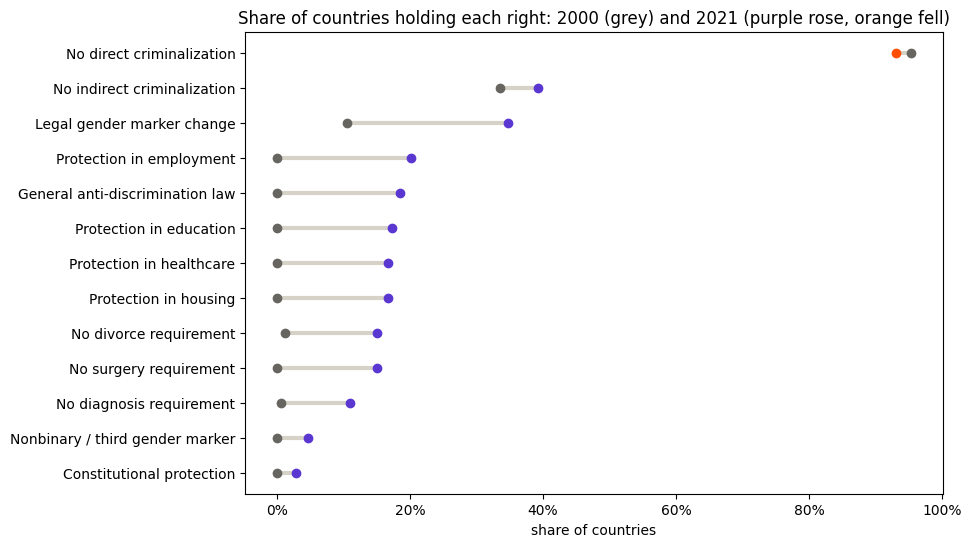

In [167]:
held_2000 = d2000[list(held_value)].eq(pd.Series(held_value)).mean()
held_2021 = d2021[list(held_value)].eq(pd.Series(held_value)).mean()
shares = pd.DataFrame({"2000": held_2000, "2021": held_2021}).rename(index=indicator_labels).sort_values("2021")

fig, ax = plt.subplots(figsize=(9, 6))
for i, (label, row) in enumerate(shares.iterrows()):
    color = "#5A37D1" if row["2021"] >= row["2000"] else "#FF4E00"
    ax.plot([row["2000"], row["2021"]], [i, i], color="#D6D2C8", lw=3, zorder=1)
    ax.scatter(row["2000"], i, color="#67655F", zorder=2, label="2000" if i == 0 else None)
    ax.scatter(row["2021"], i, color=color, zorder=2)
ax.set_yticks(range(len(shares)), shares.index)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("share of countries")
ax.set_title("Share of countries holding each right: 2000 (grey) and 2021 (purple rose, orange fell)")
plt.show()

Two things stand out. Legal gender marker change made the biggest jump of any right, and one right, no direct criminalization, is the only dot that moved left. Comparing two years doesn't show the order things happened in, so the next chart follows every year.

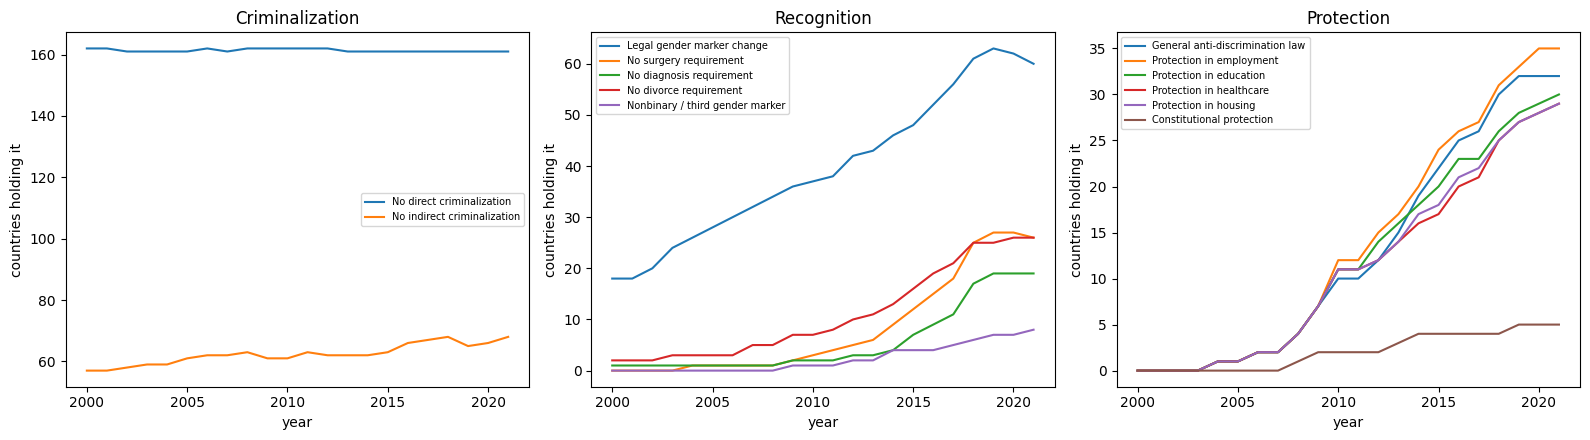

In [168]:
groups = {
    "Criminalization": ["dir_crim", "ind_crim"],
    "Recognition": ["gmc", "gmcphys", "gmcpsych", "gmcdiv", "nb3g"],
    "Protection": ["adp_general", "adp_employment", "adp_education", "adp_healthcare", "adp_housing", "adp_constitution"],
}
scored = df[df["trip_score"].notna()]
held_by_year = scored[list(held_value)].eq(pd.Series(held_value)).groupby(scored["year"]).sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (group, columns) in zip(axes, groups.items()):
    held_by_year[columns].rename(columns=indicator_labels).plot(ax=ax, title=group)
    ax.set_ylabel("countries holding it")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

Legal gender marker change climbs from 2002 on, while every protection line sits at zero until 2004 and most of its growth comes after 2010. That is the "recognition before protection" order. Gender marker change also turns down after 2019, a first hint of losses.

The criminalization panel hides something: the count without direct criminalization barely moves, but the number of countries in the data grows from 170 to 173, so the count of countries *with* direct criminalization can still rise. The questions below put numbers on each of those lines.

### Direct criminalization, 2000 vs 2021


In [169]:
print(int(d2000["dir_crim"].sum()), "->", int(d2021["dir_crim"].sum()))


8 -> 12


### Gender marker change, 2000 vs 2021, and where


In [170]:
print("countries:", int(d2000["gmc"].sum()), "->", int(d2021["gmc"].sum()))

americas_2000 = d2000[d2000["e_regionpol_6C"] == "L. American and the Caribbean"]
americas_2021 = d2021[d2021["e_regionpol_6C"] == "L. American and the Caribbean"]
print("in the Americas, 2000:", int(americas_2000["gmc"].sum()), " | 2021:", int(americas_2021["gmc"].sum()))


countries: 18 -> 60
in the Americas, 2000: 0  | 2021: 10


### Where were the countries with gender marker change in 2000?

In [171]:
print(d2000[d2000["gmc"] == 1]["e_regionpol_6C"].value_counts())

e_regionpol_6C
W. Europe and N. America     7
E. Europe and C. Asia        7
Middle East and N. Africa    3
Sub-Saharan Africa           1
Name: count, dtype: int64


### Anti-discrimination protections, 2000 vs 2021


In [172]:
for col in ["adp_employment", "adp_education", "adp_healthcare", "adp_housing"]:
    print(col, f"{d2000[col].mean():.1%} -> {d2021[col].mean():.1%}")


adp_employment 0.0% -> 20.2%
adp_education 0.0% -> 17.3%
adp_healthcare 0.0% -> 16.8%
adp_housing 0.0% -> 16.8%


### Did any country have an anti-discrimination law in 2000?

In [173]:
adp_cols = ["adp_general", "adp_employment", "adp_education", "adp_healthcare", "adp_housing", "adp_constitution"]

print("countries with any anti-discrimination protection in 2000:", int((d2000[adp_cols] == 1).any(axis=1).sum()))

countries with any anti-discrimination protection in 2000: 0


### Who has constitutional protection in 2021?


In [174]:
print(d2021[d2021["adp_constitution"] == 1]["country_name"].tolist())


['Bolivia', 'Ecuador', 'Cuba', 'Fiji', 'Malta']


### Who has a nonbinary / third-gender marker in 2021?


In [175]:
nb_2021 = d2021[d2021["nb3g"] == 1]
print(len(nb_2021), nb_2021["country_name"].tolist())


8 ['Bangladesh', 'Pakistan', 'Argentina', 'India', 'Nepal', 'Uruguay', 'Iceland', 'Malta']


### Gains and losses over the years

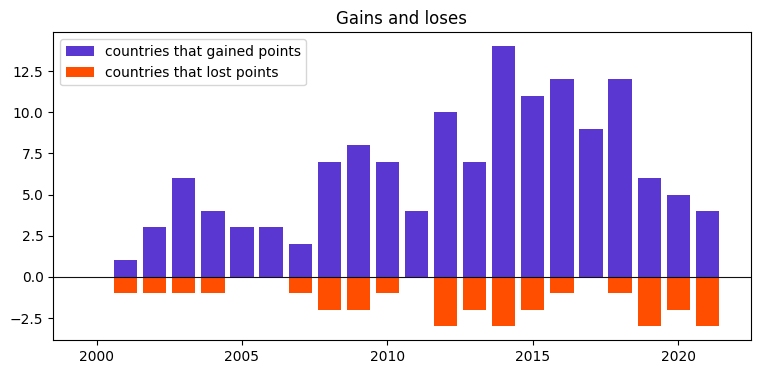

In [176]:
moves = yearly.groupby("year")["change"].agg(gained=lambda s: (s > 0).sum(), lost=lambda s: (s < 0).sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(moves.index, moves["gained"], color="#5A37D1", label="countries that gained points")
ax.bar(moves.index, -moves["lost"], color="#FF4E00", label="countries that lost points")
ax.axhline(0, color="#111111", lw=0.8)
ax.set_title("Gains and loses")
ax.legend()
plt.show()

21 countries lost points in at least one year


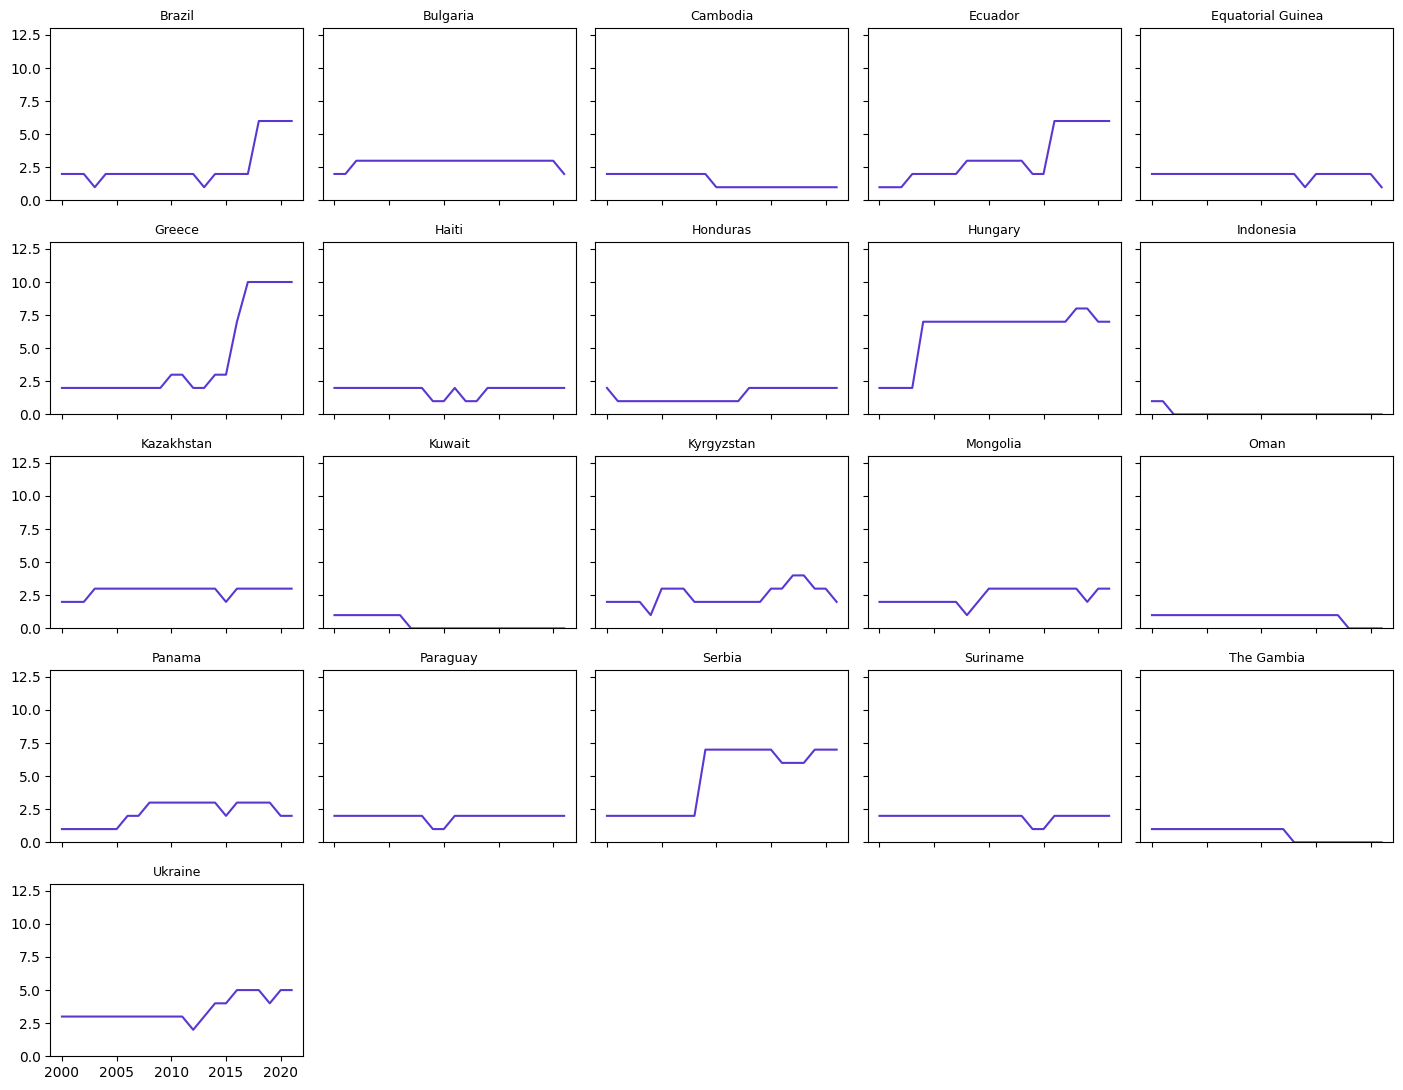

In [177]:
fell = yearly[yearly["change"] < 0]["country_name"].unique()
print(len(fell), "countries lost points in at least one year")

cols = 5
rows = int(np.ceil(len(fell) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 2.2 * rows), sharex=True, sharey=True)
for ax, name in zip(axes.flat, sorted(fell)):
    country = yearly[yearly["country_name"] == name]
    ax.plot(country["year"], country["trip_score"], color="#5A37D1")
    ax.set_title(name, fontsize=9)
    ax.set_ylim(0, 13)
for ax in axes.flat[len(fell):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Countries that lost at least one protection, at any point 2000-2021


In [178]:
# held_value is defined under the indicator table at the top
countries_that_lost = []
for country_id, country_rows in df.groupby("country_text_id"):
    country_rows = country_rows.sort_values("year")
    lost_something = False
    for column, held in held_value.items():
        had_it_before = False
        for value in country_rows[column]:
            if pd.isna(value):
                continue
            has_it_now = (value == held)
            if had_it_before and not has_it_now:
                lost_something = True
            had_it_before = has_it_now
    if lost_something:
        countries_that_lost.append(country_id)

print(len(countries_that_lost))


21


### Which six ended lower than they started?


In [179]:
lower_2021 = both_years[both_years["trip_score_2021"] < both_years["trip_score_2000"]]
print(lower_2021.merge(df[["country_text_id", "country_name"]].drop_duplicates())[["country_name"]])


        country_name
0           Cambodia
1          Indonesia
2         The Gambia
3  Equatorial Guinea
4             Kuwait
5               Oman


### When did those four countries newly criminalize trans people?


In [180]:
for name in ["Indonesia", "Kuwait", "The Gambia", "Oman"]:
    rows = df[df["country_name"] == name].sort_values("year")
    newly_criminal = rows[(rows["dir_crim"] == 1) & (rows["dir_crim"].shift(1) == 0)]
    print(name, newly_criminal["year"].tolist())


Indonesia [2002.0]
Kuwait [2007.0]
The Gambia [2013.0]
Oman [2018.0]


### Hungary, Bulgaria, Kyrgyzstan losing legal gender change


In [181]:
for name in ["Hungary", "Bulgaria", "Kyrgyzstan"]:
    rows = df[df["country_name"] == name].sort_values("year")
    lost_it = rows[(rows["gmc"] == 0) & (rows["gmc"].shift(1) == 1)]
    print(name, lost_it["year"].tolist())


Hungary [2020.0]
Bulgaria [2021.0]
Kyrgyzstan [2021.0]


### Of the 21 countries that lost a protection, how many only lost indirect-criminalization status?


In [182]:
only_ind_crim_loss = 0
for country_id, country_rows in df.groupby("country_text_id"):
    country_rows = country_rows.sort_values("year")
    columns_lost = set()
    for column, held in held_value.items():
        had_it_before = False
        for value in country_rows[column]:
            if pd.isna(value):
                continue
            has_it_now = (value == held)
            if had_it_before and not has_it_now:
                columns_lost.add(column)
            had_it_before = has_it_now
    if columns_lost == {"ind_crim"}:
        only_ind_crim_loss += 1

print(only_ind_crim_loss)


14


### How often do trans rights and LGB rights move together (2020)?


In [183]:
d2020 = df[(df["year"] == 2020)].dropna(subset=["trip_percent", "lgb_percent"])
gap = (d2020["trip_percent"] - d2020["lgb_percent"]).abs()
similar = (gap < 0.15).sum()
print(similar, "of", len(d2020))


134 of 173


### Trans rights vs. LGB rights, 2020

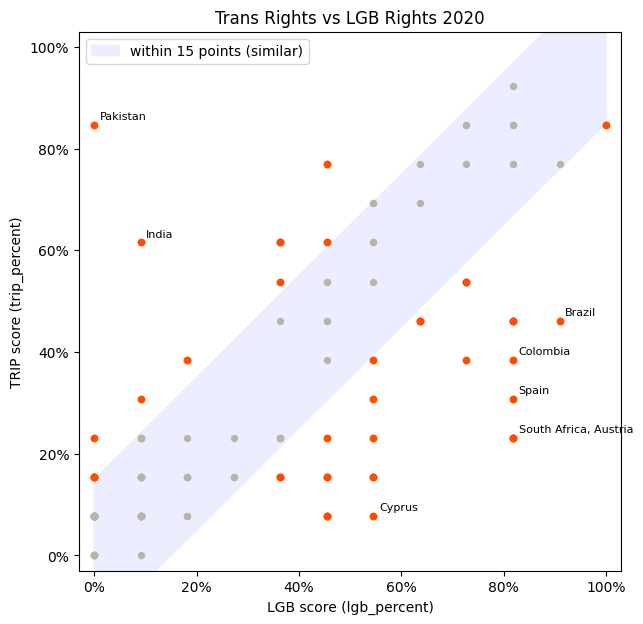

In [184]:
fig, ax = plt.subplots(figsize=(7, 7))
line = np.linspace(0, 1, 50)
ax.fill_between(line, line - 0.15, line + 0.15, color="#ECEDFF", label="within 15 points (similar)")
similar_rows = gap < 0.15
ax.scatter(d2020["lgb_percent"][similar_rows], d2020["trip_percent"][similar_rows], color="#B9B4A8", s=18)
ax.scatter(d2020["lgb_percent"][~similar_rows], d2020["trip_percent"][~similar_rows], color="#FF4E00", s=22)

biggest_gaps = d2020.assign(gap=gap).nlargest(8, "gap")
for (lgb, trip), group in biggest_gaps.groupby(["lgb_percent", "trip_percent"]):
    ax.annotate(", ".join(group["country_name"]), (lgb, trip),
                xytext=(4, 4), textcoords="offset points", fontsize=8)

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("LGB score (lgb_percent)")
ax.set_ylabel("TRIP score (trip_percent)")
ax.set_title("Trans Rights vs LGB Rights 2020")
ax.legend(loc="upper left")
plt.show()

### When they split, which side is left behind?

In [185]:
split = d2020[gap >= 0.15]
print((split["trip_percent"] < split["lgb_percent"]).sum(), "countries where trans rights are lower")
print((split["trip_percent"] > split["lgb_percent"]).sum(), "countries where trans rights are higher")

26 countries where trans rights are lower
13 countries where trans rights are higher


### The six country cards


In [186]:
cards = ["Argentina", "India", "Austria", "Pakistan", "Iran", "United States of America"]
print(d2021[d2021["country_name"].isin(cards)][["country_name", "trip_score", "trip_percent"]])


                  country_name  trip_score  trip_percent
367   United States of America         5.0      0.384615
551                   Pakistan        11.0      0.846154
700                  Argentina         6.0      0.461538
746                      India         8.0      0.615385
1643                      Iran         2.0      0.153846
2977                   Austria         3.0      0.230769


### The details behind each card

In [187]:
cards_held = d2021.set_index("country_name").loc[cards, list(held_value)].eq(pd.Series(held_value)).astype(int)
print(cards_held.rename(columns=indicator_labels).T)
print()

self_id = df[(df["gmc"] == 1) & (df["gmcphys"] == 0) & (df["gmcpsych"] == 0) & (df["gmcdiv"] == 0)]
first_self_id = self_id["year"].min()
print("first year with gender change and no conditions:", first_self_id, self_id[self_id["year"] == first_self_id]["country_name"].tolist())
print("Argentina - nonbinary marker from", first_year("Argentina", "nb3g"))
print("India - gender change from", first_year("India", "gmc"), "| third gender from", first_year("India", "nb3g"),
      "| employment protection from", first_year("India", "adp_employment"))
print("Pakistan - scores before 2018:", sorted(df[(df["country_name"] == "Pakistan") & (df["year"] < 2018)]["trip_score"].unique()))
print("Iran - every score 2000-2021:", df[df["country_name"] == "Iran"]["trip_score"].unique())

country_name                     Argentina  India  Austria  Pakistan  Iran  \
No direct criminalization                1      1        1         1     1   
No indirect criminalization              0      0        1         0     0   
Legal gender marker change               1      1        1         1     1   
No surgery requirement                   1      0        0         1     0   
No diagnosis requirement                 1      0        0         1     0   
No divorce requirement                   1      0        0         1     0   
Nonbinary / third gender marker          1      1        0         1     0   
General anti-discrimination law          0      1        0         1     0   
Protection in employment                 0      1        0         1     0   
Protection in education                  0      1        0         1     0   
Protection in healthcare                 0      1        0         1     0   
Protection in housing                    0      1        0      

### Austria and Pakistan next to their LGB scores (2020)


In [188]:
both = d2020[d2020["country_name"].isin(["Austria", "Pakistan"])]
print(both[["country_name", "trip_percent", "lgb_percent"]])


     country_name  trip_percent  lgb_percent
550      Pakistan      0.846154     0.000000
2976      Austria      0.230769     0.818182


### Pakistan's and other's jump in 2018


In [189]:
pakistan = df[df["country_name"] == "Pakistan"].sort_values("year")
pakistan["yearly_gain"] = pakistan["trip_score"].diff()
print(pakistan[pakistan["year"].between(2015, 2019)][["year", "trip_score", "yearly_gain"]])

biggest_gains = df.sort_values(["country_text_id", "year"]).copy()
biggest_gains["yearly_gain"] = biggest_gains.groupby("country_text_id")["trip_score"].diff()
print(biggest_gains.nlargest(3, "yearly_gain")[["country_name", "year", "yearly_gain"]])


       year  trip_score  yearly_gain
545  2015.0         2.0          0.0
546  2016.0         2.0          0.0
547  2017.0         2.0          0.0
548  2018.0        11.0          9.0
549  2019.0        11.0          0.0
     country_name    year  yearly_gain
3480   Luxembourg  2018.0          9.0
548      Pakistan  2018.0          9.0
2169      Uruguay  2018.0          6.0


### Score vs. Wealth, 2021

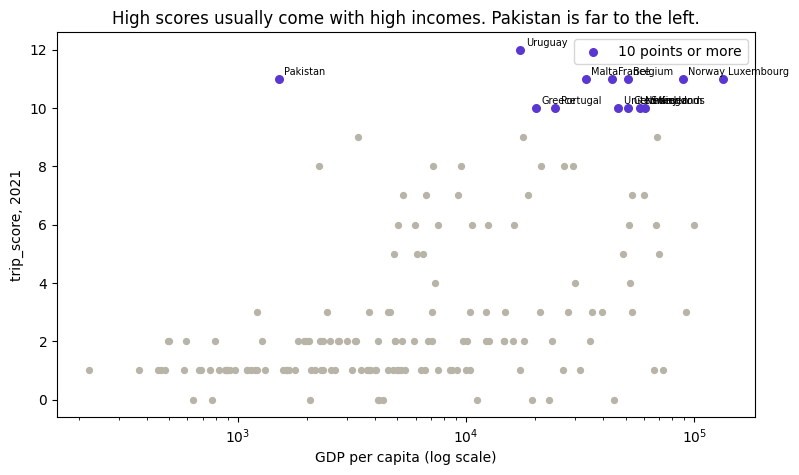

In [190]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(d2021["wb_gdppc"], d2021["trip_score"], color="#B9B4A8", s=18)
ten_plus = d2021[d2021["trip_score"] >= 10]
ax.scatter(ten_plus["wb_gdppc"], ten_plus["trip_score"], color="#5A37D1", s=30, label="10 points or more")
for _, row in ten_plus.iterrows():
    ax.annotate(row["country_name"], (row["wb_gdppc"], row["trip_score"]),
                xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (log scale)")
ax.set_ylabel("trip_score, 2021")
ax.set_title("High scores usually come with high incomes. Pakistan is far to the left.")
ax.legend()
plt.show()

### Pakistan compared to other high scorers (GDP and regime type)


In [191]:
high_scorers = d2021[d2021["trip_score"] >= 10]
print(high_scorers[["country_name", "wb_gdppc", "v2x_regime"]].sort_values("wb_gdppc"))


        country_name       wb_gdppc           v2x_regime
551         Pakistan    1505.010193  Electoral Autocracy
2172         Uruguay   17313.188348    Liberal Democracy
3345          Greece   20192.596304    Liberal Democracy
390         Portugal   24567.509265  Electoral Democracy
3552           Malta   33486.671984  Electoral Democracy
1574          France   43658.978978    Liberal Democracy
2149  United Kingdom   46510.282782    Liberal Democracy
1597         Germany   51203.554473    Liberal Democracy
3046         Belgium   51247.014353    Liberal Democracy
1919     Netherlands   57767.878811    Liberal Democracy
68            Sweden   61028.738060    Liberal Democracy
3644          Norway   89154.276093    Liberal Democracy
3483      Luxembourg  133590.146976    Liberal Democracy


### Iran compared to the rest of the Middle East & North Africa


In [192]:
mena = d2021[d2021["e_regionpol_6C"] == "Middle East and N. Africa"]
print(mena[["country_name", "trip_score"]].sort_values("trip_score", ascending=False))
print("share scoring 0 or 1:", (mena["trip_score"] <= 1).mean())


              country_name  trip_score
3414                Israel         4.0
1643                  Iran         2.0
2103                Turkey         2.0
2678                 Libya         1.0
275                  Yemen         1.0
252                  Egypt         1.0
1896               Morocco         1.0
2057                 Syria         1.0
1988                 Qatar         1.0
2080               Tunisia         1.0
1666                  Iraq         1.0
3000               Bahrain         1.0
2195               Algeria         1.0
861                Lebanon         0.0
1735                Jordan         0.0
3437                Kuwait         0.0
3667                  Oman         0.0
3759          Saudi Arabia         0.0
3943  United Arab Emirates         0.0
share scoring 0 or 1: 0.8421052631578947


---
## Section 4: "Every country, every year"


### Every country, every year

Rows are countries sorted by their 2021 score (then 2000), columns are years. Colours are the article's six score classes. The line marks the bottom quarter (44 countries).

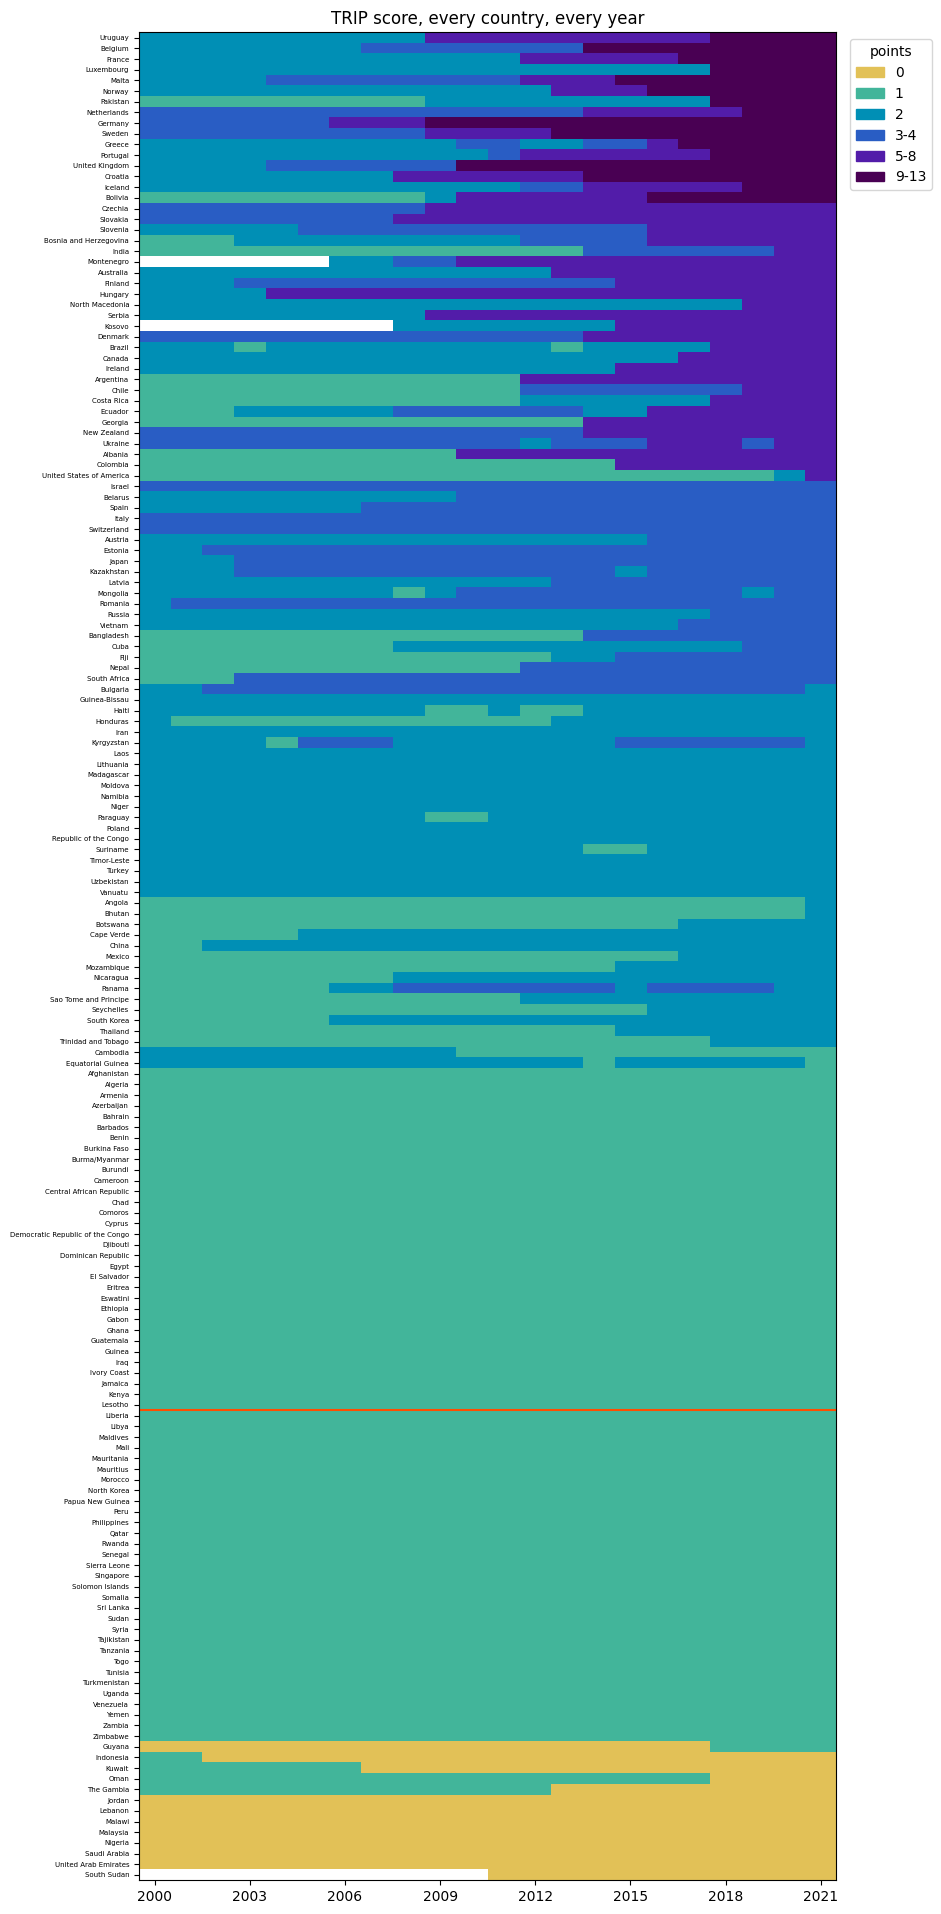

In [193]:
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch

class_colors = ["#E2C157", "#42B59A", "#008FB5", "#295DC4", "#521CA9", "#490053"]
class_labels = ["0", "1", "2", "3-4", "5-8", "9-13"]
norm = BoundaryNorm([0, 1, 2, 3, 5, 9, 14], len(class_colors))

every_year = df.pivot_table(index="country_name", columns="year", values="trip_score")
every_year = every_year.sort_values([2021, 2000], ascending=False)

fig, ax = plt.subplots(figsize=(9, 24))
ax.imshow(every_year, aspect="auto", cmap=ListedColormap(class_colors), norm=norm, interpolation="none")
ax.set_xticks(range(0, 22, 3), [int(year) for year in every_year.columns[::3]])
ax.set_yticks(range(len(every_year)), every_year.index, fontsize=5)
ax.axhline(len(every_year) - 44 - 0.5, color="#FF4E00", lw=1.5)
ax.legend([Patch(color=c) for c in class_colors], class_labels, title="points",
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("TRIP score, every country, every year")
plt.show()

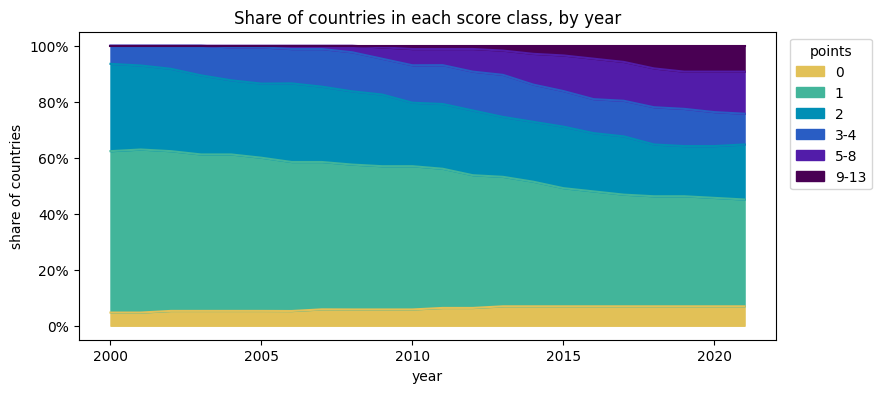

In [194]:
score_class = pd.cut(scored["trip_score"], bins=[-0.5, 0.5, 1.5, 2.5, 4.5, 8.5, 13.5], labels=class_labels)
class_share = pd.crosstab(scored["year"], score_class, normalize="index")

ax = class_share.plot.area(figsize=(9, 4), color=class_colors)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("share of countries")
ax.set_title("Share of countries in each score class, by year")
ax.legend(title="points", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### Share of countries with 1 or 2 points in 2000


In [195]:
share_12 = d2000["trip_score"].isin([1, 2]).mean()
print(f"{share_12:.1%}")


88.8%


### Highest score anyone had in 2000


In [196]:
print(int(d2000["trip_score"].max()))


4


### Countries with 5+ points, by 2011


In [197]:
d2011 = df[(df["year"] == 2011) & df["trip_score"].notna()]
print((d2011["trip_score"] >= 5).sum())


12


### Countries with 5+ and 9+ points by 2021


In [198]:
print("5 or more:", (d2021["trip_score"] >= 5).sum())
print("9 or more:", (d2021["trip_score"] >= 9).sum())


5 or more: 42
9 or more: 16


### The bottom quarter: how many countries, how many unchanged


In [199]:
bottom_quarter = d2021.nsmallest(44, "trip_score")
unchanged_in_bottom = bottom_quarter.merge(
    scores_2000, on="country_text_id", suffixes=("_2021", "_2000")
)
same_score = unchanged_in_bottom["trip_score_2021"] == unchanged_in_bottom["trip_score_2000"]
print(len(bottom_quarter), "countries, ", same_score.sum(), "unchanged")


44 countries,  38 unchanged


---
## A note on the numbers that didn't match

Two of the numbers above come out a little different from what's in
`article-text.md`:

- **"88 countries unchanged 2000-2021"** — I get **93**.
- **"39 of the bottom 44 unchanged"** — I get **38**, and that number
  moves around depending on how ties are broken: 66 countries are tied
  at exactly 1 point in 2021, so which ones count as "the bottom 44" is
  a little arbitrary.

Everything else — every other number in Sections 1 through 4 — matched
exactly. Worth a look before the next edit of the article, but not
something to worry about right now.
